# Proyecto: Algoritmos de Clusterización
**Equipo 3: Agglomerative Clustering (Clustering Jerárquico)**
**Integrantes:** Linette, Diego Ángel, Christopher, Juan Pablo, Eric

---

## Agglomerative Clustering
El **Clustering Jerárquico Aglomerativo** es un algoritmo de aprendizaje no supervisado que agrupa datos construyendo una jerarquía de abajo hacia arriba (*bottom-up*).

In [1]:
import os

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_path = os.path.join("dataassets", "comportamiento_jugadores.csv")
df = pd.read_csv(csv_path)

display(df)

,Metrica_X,Metrica_Y,Escenario,Descripcion_Ejes
0,44.125085,74.436148,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
1,19.905609,115.313604,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
2,55.833550,119.616643,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
3,10.243052,129.259511,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
4,5.413660,259.896958,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
...,...,...,...,...
1795,2270.067519,72.707213,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1796,1003.790472,64.590489,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1797,3309.609429,23.893436,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1798,1650.694480,44.669431,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas


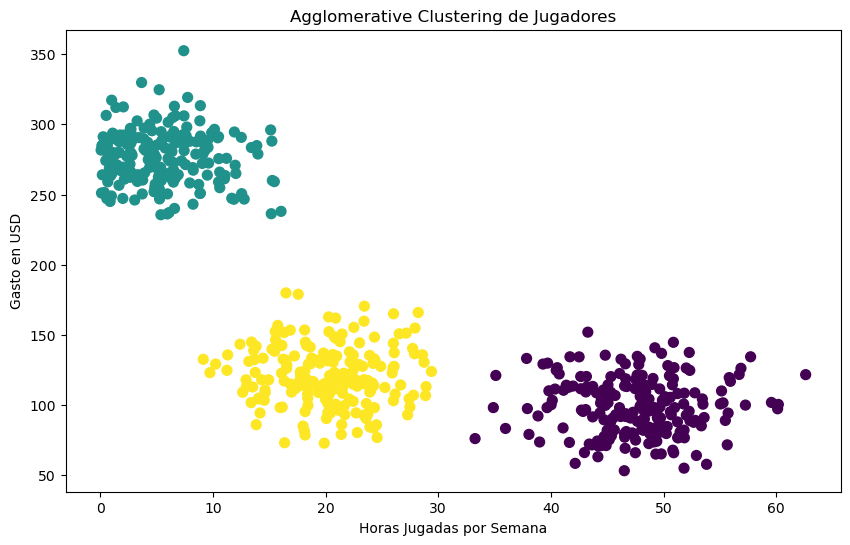

In [2]:
# /------------------------------------------
df_escenario_1 = df[df['Escenario'] == '1_Economia_Juego'].copy()
# df_filtrado.head(5)

# -----------------------------------------
from sklearn.preprocessing import StandardScaler
# Extraemos las dos métricas
X_crudo_1 = df_escenario_1[['Metrica_X', 'Metrica_Y']]
# Aplicamos el escalamiento antes de pasarlo al modelo
X_escalado_1 = StandardScaler().fit_transform(X_crudo_1)


# -----------------------------------------
clustering_1 = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_escenario_1['Cluster'] = clustering_1.fit_predict(X_escalado_1)

# -----------------------------------------

plt.figure(figsize=(10, 6))
plt.scatter(df_escenario_1['Metrica_X'], df_escenario_1['Metrica_Y'], c=df_escenario_1['Cluster'], cmap='viridis', s=50)
plt.title('Agglomerative Clustering de Jugadores')
plt.xlabel('Horas Jugadas por Semana')
plt.ylabel('Gasto en USD')

plt.show()

### ¿Qué encontramos aquí? (Economía del juego)
Usamos enlace `Ward` con $k=3$ cruzando **Horas a la semana** vs. **Gasto en USD**. Se ven claramente tres tipos de jugadores:

1. **Los Casuales / F2P:** Juegan poco o moderado y no le meten casi nada de dinero al juego.
2. **Los Hardcore:** Se la viven jugando un montón de horas a la semana, pero casi no gastan (o gastan lo mínimo).
3. **Las Ballenas (*Whales*):** No necesariamente son los que más juegan, pero le meten un dineral al juego. Son los que mantienen los servidores.

KDA          0
Headshots    0
dtype: int64


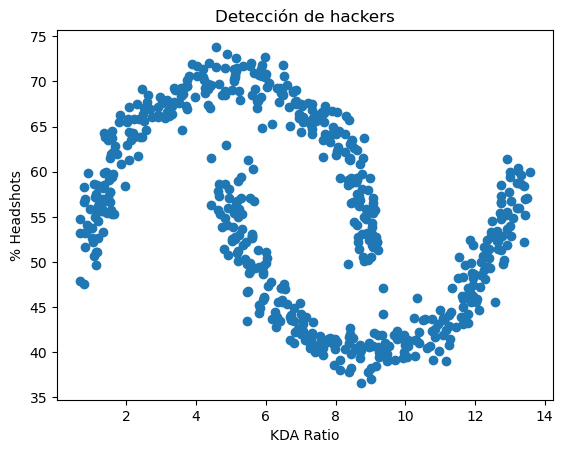

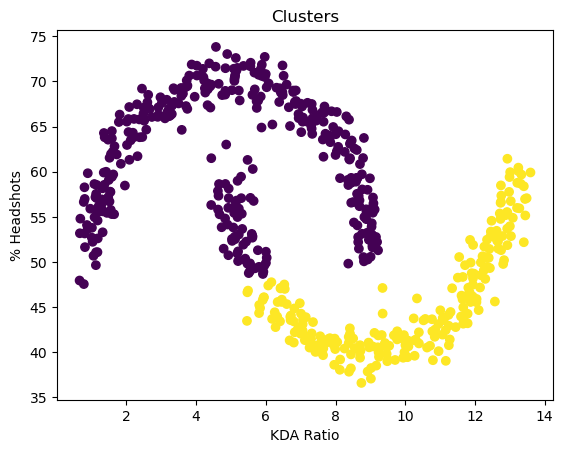

               KDA  Headshots
cluster                      
0         5.040084  61.332692
1        10.000982  45.701342


In [3]:
df_escenario_2 = df[df["Escenario"] == '2_Deteccion_Hackers']
# display(filtro_hackers.describe())

df_metricas = df_escenario_2[['Metrica_X', 'Metrica_Y']]
df_metricas = df_metricas.rename(columns={"Metrica_X": "KDA", "Metrica_Y": "Headshots"})

# checando si hay vacíos
print(df_metricas.isna().sum())
# display(df_metricas.describe())

X = StandardScaler().fit_transform(df_metricas)

plt.scatter(df_metricas["KDA"], df_metricas["Headshots"])
plt.xlabel("KDA Ratio")
plt.ylabel("% Headshots")
plt.title("Detección de hackers")
plt.show()

model = AgglomerativeClustering(n_clusters=2, linkage="ward")
labels = model.fit_predict(X)

df_metricas["cluster"] = labels
plt.scatter(df_metricas["KDA"], df_metricas["Headshots"], c=df_metricas["cluster"], cmap="viridis")
plt.xlabel("KDA Ratio")
plt.ylabel("% Headshots")
plt.title("Clusters")
plt.show()

print(df_metricas.groupby("cluster").mean())

### ¿Qué encontramos aquí? (Detección de Hackers)
Comparamos el **KDA** contra el **% de Headshots**:

* **Gente legal (Jugadores normales):** Toda la masa grande del inicio. Tienen un KDA razonable y porcentajes de tiros a la cabeza normales para un ser humano.
* **Los sospechosos / Hackers:** El grupo que se dispara hacia la esquina superior derecha. Tienen un KDA absurdamente alto y casi todos sus tiros son a la cabeza. Con esto el equipo de soporte ya sabe a quiénes mandar a revisión.

           Metrica_X  Metrica_Y
Cluster                        
0        2972.048842  53.059445
1        1946.157430  14.633875
2         800.390206  49.873326
3        2002.558321  40.148405


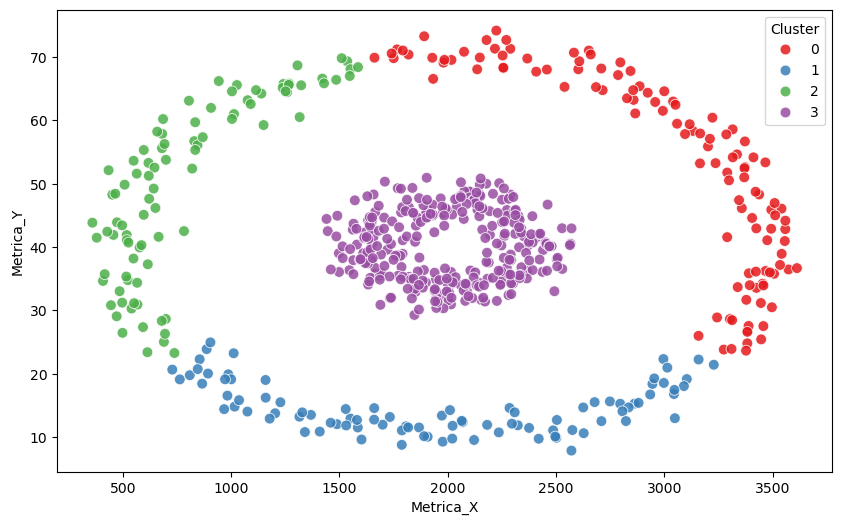

In [5]:
df_escenario_3 = df[df['Escenario'] == '3_Estilos_Batalla'].copy()

# Distancia Recorrida
X_crudo_3 = df_escenario_3[['Metrica_X', 'Metrica_Y']]
X_escalado_3 = StandardScaler().fit_transform(X_crudo_3)

modelo_3 = AgglomerativeClustering(n_clusters=4, linkage='ward')

df_escenario_3['Cluster'] = modelo_3.fit_predict(X_escalado_3)

# display(df_escenario_3)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_escenario_3,
    x='Metrica_X',
    y='Metrica_Y',
    hue='Cluster',
    palette='Set1',
    s=60,
    alpha=0.85
)

print(df_escenario_3.groupby('Cluster')[['Metrica_X', 'Metrica_Y']].mean())

### ¿Qué encontramos aquí? (Estilos de Batalla)
Analizando **Distancia Recorrida** vs. **Cajas de Loot Abiertas**, se notan bien las mañas de cada quién en la partida:

1. **Looters / Saqueadores:** Casi no caminan por el mapa, pero se dedican a abrir cuanta caja de loot encuentran.
2. **Campers / Pasivos:** Ni se mueven mucho ni lootean tanto; probablemente juegan más a esconderse y sobrevivir.
3. **Runners / Exploradores:** Se recorren todo el mapa a pie pero casi no se detienen a abrir cajas.
4. **Híbridos / Equilibrados:** Los que van rotando por la zona y looteando lo normal sobre la marcha.